  Using cached scikit_learn-1.9.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (9.2 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached scipy-1.18.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (35.3 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn]0m 5/6 [scikit-learn]]

--- K-MEANS RESULTS ---
Final Cluster Centers (Standardized):
 [[-0.1933 -0.2259  0.4206 -0.3204 -0.0399 -0.6887 -0.6537]
 [-1.0371 -1

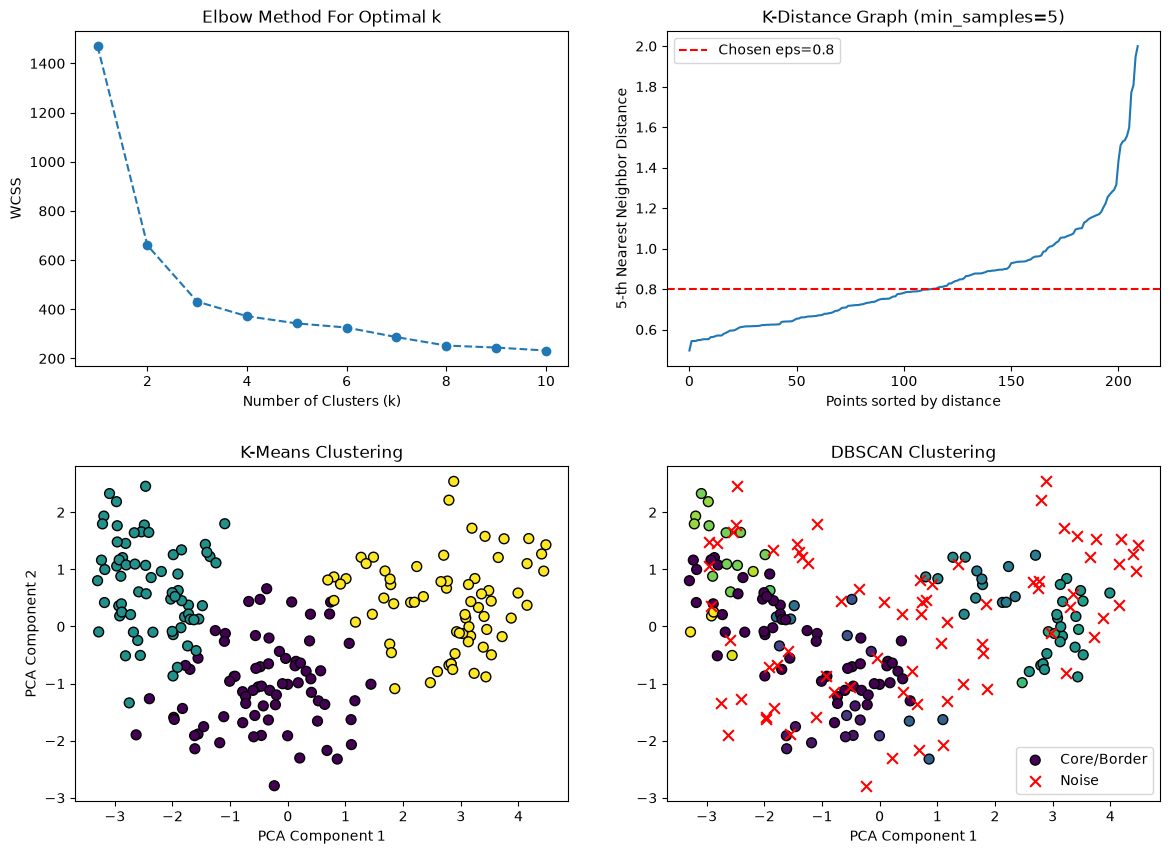


--- EVALUATION AGAINST TRUE LABELS ---
K-Means Adjusted Rand Index: 0.8227
DBSCAN Adjusted Rand Index:  0.1105


In [2]:
!pip install scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score

class KMeansScratch:
    def __init__(self, k=3, max_iters=100, random_state=42):
        self.k = k
        self.max_iters = max_iters
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        
    def fit(self, X):
        np.random.seed(self.random_state)
        idx = np.random.choice(len(X), self.k, replace=False)
        self.centroids = X[idx]
        
        for _ in range(self.max_iters):
            distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
            self.labels_ = np.argmin(distances, axis=1)
            
            new_centroids = np.array([
                X[self.labels_ == i].mean(axis=0) if np.sum(self.labels_ == i) > 0 else self.centroids[i]
                for i in range(self.k)
            ])
            
            if np.all(self.centroids == new_centroids):
                break
            self.centroids = new_centroids
            
    def get_wcss(self, X):
        distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
        min_distances = np.min(distances, axis=1)
        return np.sum(min_distances**2)

class DBSCANScratch:
    def __init__(self, eps=0.5, min_samples=5):
        self.eps = eps
        self.min_samples = min_samples
        self.labels_ = None
        
    def fit(self, X):
        n_samples = X.shape[0]
        self.labels_ = np.full(n_samples, -1)
        cluster_id = 0
        distances = np.linalg.norm(X[:, np.newaxis] - X, axis=2)
        visited = np.zeros(n_samples, dtype=bool)
        
        for i in range(n_samples):
            if visited[i]:
                continue
            visited[i] = True
            
            neighbors = np.where(distances[i] <= self.eps)[0]
            
            if len(neighbors) < self.min_samples:
                self.labels_[i] = -1 
            else:
                self._expand_cluster(visited, distances, i, neighbors, cluster_id)
                cluster_id += 1
                
    def _expand_cluster(self, visited, distances, point_idx, neighbors, cluster_id):
        self.labels_[point_idx] = cluster_id
        
        j = 0
        while j < len(neighbors):
            neighbor = neighbors[j]
            
            if not visited[neighbor]:
                visited[neighbor] = True
                new_neighbors = np.where(distances[neighbor] <= self.eps)[0]
                if len(new_neighbors) >= self.min_samples:
                    neighbors = np.unique(np.concatenate((neighbors, new_neighbors)))
                    
            if self.labels_[neighbor] == -1:
                self.labels_[neighbor] = cluster_id
            j += 1

def load_dataset(filepath):
    df = pd.read_csv(filepath)
    X = df.drop('Class', axis=1).values
    y_true = df['Class'].values
    return X, y_true

def scale_features(X):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    return X_scaled

def reduce_dimensions_for_plotting(X_scaled, n_components=2):
    pca = PCA(n_components=n_components)
    X_pca = pca.fit_transform(X_scaled)
    return X_pca

def calculate_elbow_method_wcss(X_scaled, max_k=10):
    wcss_scores = []
    k_range = range(1, max_k + 1)
    
    for k in k_range:
        km = KMeansScratch(k=k, random_state=42)
        km.fit(X_scaled)
        wcss_scores.append(km.get_wcss(X_scaled))
        
    return k_range, wcss_scores

def fit_optimal_kmeans(X_scaled, optimal_k):
    kmeans = KMeansScratch(k=optimal_k, random_state=42)
    kmeans.fit(X_scaled)
    
    print("\n--- K-MEANS RESULTS ---")
    print("Final Cluster Centers (Standardized):\n", np.round(kmeans.centroids, 4))
    return kmeans

def calculate_k_distances(X_scaled, min_samples):
    neighbors_model = NearestNeighbors(n_neighbors=min_samples)
    neighbors_fit = neighbors_model.fit(X_scaled)
    distances, _ = neighbors_fit.kneighbors(X_scaled)
    
    sorted_k_distances = np.sort(distances[:, -1]) 
    return sorted_k_distances

def fit_optimal_dbscan(X_scaled, eps, min_samples):
    dbscan = DBSCANScratch(eps=eps, min_samples=min_samples)
    dbscan.fit(X_scaled)
    
    n_clusters = len(set(dbscan.labels_)) - (1 if -1 in dbscan.labels_ else 0)
    n_noise = list(dbscan.labels_).count(-1)
    
    print("\n--- DBSCAN RESULTS ---")
    print(f"Number of Clusters Formed: {n_clusters}")
    print(f"Total Number of Noise Points: {n_noise}")
    return dbscan

def plot_elbow_curve(ax, k_range, wcss_scores):
    ax.plot(k_range, wcss_scores, marker='o', linestyle='--')
    ax.set_title('Elbow Method For Optimal k')
    ax.set_xlabel('Number of Clusters (k)')
    ax.set_ylabel('WCSS')

def plot_k_distance_graph(ax, k_distances, min_samples, chosen_eps):
    ax.plot(k_distances)
    ax.set_title(f'K-Distance Graph (min_samples={min_samples})')
    ax.set_xlabel('Points sorted by distance')
    ax.set_ylabel(f'{min_samples}-th Nearest Neighbor Distance')
    ax.axhline(y=chosen_eps, color='r', linestyle='--', label=f'Chosen eps={chosen_eps}')
    ax.legend()

def plot_kmeans_clusters(ax, X_pca, labels):
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', edgecolor='k', s=50)
    ax.set_title('K-Means Clustering')
    ax.set_xlabel('PCA Component 1')
    ax.set_ylabel('PCA Component 2')

def plot_dbscan_clusters(ax, X_pca, labels):
    mask_noise = labels == -1
    mask_core = labels != -1
    
    ax.scatter(X_pca[mask_core, 0], X_pca[mask_core, 1], c=labels[mask_core], 
               cmap='viridis', edgecolor='k', s=50, label='Core/Border')
               
    ax.scatter(X_pca[mask_noise, 0], X_pca[mask_noise, 1], c='red', marker='x', 
               s=60, label='Noise')
               
    ax.set_title('DBSCAN Clustering')
    ax.set_xlabel('PCA Component 1')
    ax.legend()

def print_evaluation_metrics(y_true, kmeans_labels, dbscan_labels):
    ari_kmeans = adjusted_rand_score(y_true, kmeans_labels)
    ari_dbscan = adjusted_rand_score(y_true, dbscan_labels)
    
    print("\n--- EVALUATION AGAINST TRUE LABELS ---")
    print(f"K-Means Adjusted Rand Index: {ari_kmeans:.4f}")
    print(f"DBSCAN Adjusted Rand Index:  {ari_dbscan:.4f}")

def main():
    X, y_true = load_dataset('seeds_data.csv')
    X_scaled = scale_features(X)
    
    k_range, wcss_scores = calculate_elbow_method_wcss(X_scaled, max_k=10)
    kmeans_model = fit_optimal_kmeans(X_scaled, optimal_k=3)
    
    chosen_min_samples = 5
    chosen_eps = 0.8
    k_distances = calculate_k_distances(X_scaled, min_samples=chosen_min_samples)
    dbscan_model = fit_optimal_dbscan(X_scaled, eps=chosen_eps, min_samples=chosen_min_samples)
    
    X_pca = reduce_dimensions_for_plotting(X_scaled)
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    plt.subplots_adjust(hspace=0.3)
    
    plot_elbow_curve(axes[0, 0], k_range, wcss_scores)
    plot_k_distance_graph(axes[0, 1], k_distances, chosen_min_samples, chosen_eps)
    plot_kmeans_clusters(axes[1, 0], X_pca, kmeans_model.labels_)
    plot_dbscan_clusters(axes[1, 1], X_pca, dbscan_model.labels_)
    
    plt.show()
    
    print_evaluation_metrics(y_true, kmeans_model.labels_, dbscan_model.labels_)

if __name__ == "__main__":
    main()